# Single-Qubit Gates

Each cell applies one gate to a single qubit, prints the state, measures it
1024 times and draws the circuit. Every qubit starts in |0⟩.

Z, S, T, S† and T† only change the **phase** of |1⟩, which cannot be seen on |0⟩.
So those cells first apply H to make |+⟩ = (|0⟩ + |1⟩)/√2. The phase then
shows up in the amplitude of |1⟩, while the measured counts stay 50/50,
because a phase does not change the probabilities.

### 1. Hadamard gate (H)
Creates a superposition: |0⟩ → |+⟩ = (|0⟩ + |1⟩)/√2, so 0 and 1 are each measured about half the time.

State [amplitude of |0>, amplitude of |1>]: [0.7071+0.j 0.7071+0.j]
Counts (1024 shots): {'0': 505, '1': 519}


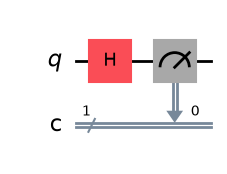

In [1]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
import numpy as np

q = QuantumRegister(1, 'q')
c = ClassicalRegister(1, 'c')
qc = QuantumCircuit(q, c)

# --- Gate ---
qc.h(q[0])            # H gate: |0> -> (|0> + |1>)/sqrt(2)

# --- State before measurement ---
print("State [amplitude of |0>, amplitude of |1>]:", np.round(Statevector(qc).data, 4))

# --- Measurement ---
qc.measure(q[0], c[0])
counts = AerSimulator().run(qc, shots=1024).result().get_counts()
print("Counts (1024 shots):", counts)

qc.draw(output='mpl')   # last line -> auto-renders circuit diagram

### 2. X gate (NOT)
Flips the qubit: |0⟩ → |1⟩. Every shot measures 1.

State [amplitude of |0>, amplitude of |1>]: [0.+0.j 1.+0.j]
Counts (1024 shots): {'1': 1024}


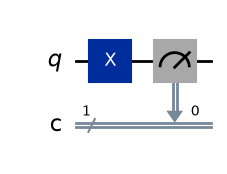

In [2]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
import numpy as np

q = QuantumRegister(1, 'q')
c = ClassicalRegister(1, 'c')
qc = QuantumCircuit(q, c)

# --- Gate ---
qc.x(q[0])            # X gate: |0> -> |1>

# --- State before measurement ---
print("State [amplitude of |0>, amplitude of |1>]:", np.round(Statevector(qc).data, 4))

# --- Measurement ---
qc.measure(q[0], c[0])
counts = AerSimulator().run(qc, shots=1024).result().get_counts()
print("Counts (1024 shots):", counts)

qc.draw(output='mpl')   # last line -> auto-renders circuit diagram

### 3. Y gate
Flips the qubit and adds a phase *i*: |0⟩ → *i*|1⟩. Every shot measures 1.

State [amplitude of |0>, amplitude of |1>]: [0.+0.j 0.+1.j]
Counts (1024 shots): {'1': 1024}


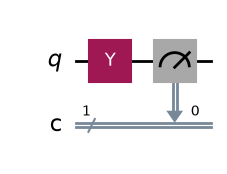

In [3]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
import numpy as np

q = QuantumRegister(1, 'q')
c = ClassicalRegister(1, 'c')
qc = QuantumCircuit(q, c)

# --- Gate ---
qc.y(q[0])            # Y gate: |0> -> i|1>

# --- State before measurement ---
print("State [amplitude of |0>, amplitude of |1>]:", np.round(Statevector(qc).data, 4))

# --- Measurement ---
qc.measure(q[0], c[0])
counts = AerSimulator().run(qc, shots=1024).result().get_counts()
print("Counts (1024 shots):", counts)

qc.draw(output='mpl')   # last line -> auto-renders circuit diagram

### 4. Z gate
Flips the sign of |1⟩: |+⟩ → |−⟩ = (|0⟩ − |1⟩)/√2.

State [amplitude of |0>, amplitude of |1>]: [ 0.7071+0.j -0.7071+0.j]
Counts (1024 shots): {'0': 521, '1': 503}


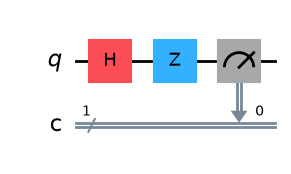

In [4]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
import numpy as np

q = QuantumRegister(1, 'q')
c = ClassicalRegister(1, 'c')
qc = QuantumCircuit(q, c)

# --- Prep step: H makes |+> so the phase change is visible ---
qc.h(q[0])            # |0> -> |+> = (|0> + |1>)/sqrt(2)

# --- Gate ---
qc.z(q[0])            # Z gate: phase -1 on |1>

# --- State before measurement ---
print("State [amplitude of |0>, amplitude of |1>]:", np.round(Statevector(qc).data, 4))

# --- Measurement ---
qc.measure(q[0], c[0])
counts = AerSimulator().run(qc, shots=1024).result().get_counts()
print("Counts (1024 shots):", counts)

qc.draw(output='mpl')   # last line -> auto-renders circuit diagram

### 5. S gate
Adds a phase *i* (90°) to |1⟩: |+⟩ → (|0⟩ + *i*|1⟩)/√2.

State [amplitude of |0>, amplitude of |1>]: [0.7071+0.j     0.    +0.7071j]
Counts (1024 shots): {'1': 527, '0': 497}


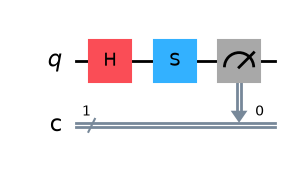

In [5]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
import numpy as np

q = QuantumRegister(1, 'q')
c = ClassicalRegister(1, 'c')
qc = QuantumCircuit(q, c)

# --- Prep step: H makes |+> so the phase change is visible ---
qc.h(q[0])            # |0> -> |+> = (|0> + |1>)/sqrt(2)

# --- Gate ---
qc.s(q[0])            # S gate: phase i on |1>

# --- State before measurement ---
print("State [amplitude of |0>, amplitude of |1>]:", np.round(Statevector(qc).data, 4))

# --- Measurement ---
qc.measure(q[0], c[0])
counts = AerSimulator().run(qc, shots=1024).result().get_counts()
print("Counts (1024 shots):", counts)

qc.draw(output='mpl')   # last line -> auto-renders circuit diagram

### 6. T gate
Adds a phase e^{iπ/4} (45°) to |1⟩: |+⟩ → (|0⟩ + e^{iπ/4}|1⟩)/√2.

State [amplitude of |0>, amplitude of |1>]: [0.7071+0.j  0.5   +0.5j]
Counts (1024 shots): {'1': 511, '0': 513}


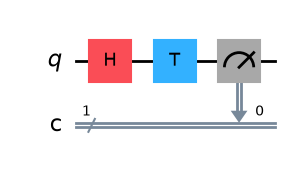

In [6]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
import numpy as np

q = QuantumRegister(1, 'q')
c = ClassicalRegister(1, 'c')
qc = QuantumCircuit(q, c)

# --- Prep step: H makes |+> so the phase change is visible ---
qc.h(q[0])            # |0> -> |+> = (|0> + |1>)/sqrt(2)

# --- Gate ---
qc.t(q[0])            # T gate: phase e^(i*pi/4) on |1>

# --- State before measurement ---
print("State [amplitude of |0>, amplitude of |1>]:", np.round(Statevector(qc).data, 4))

# --- Measurement ---
qc.measure(q[0], c[0])
counts = AerSimulator().run(qc, shots=1024).result().get_counts()
print("Counts (1024 shots):", counts)

qc.draw(output='mpl')   # last line -> auto-renders circuit diagram

### 7. S† gate (S dagger)
The inverse of S: adds a phase −*i* (−90°) to |1⟩.

State [amplitude of |0>, amplitude of |1>]: [0.7071+0.j     0.    -0.7071j]
Counts (1024 shots): {'1': 499, '0': 525}


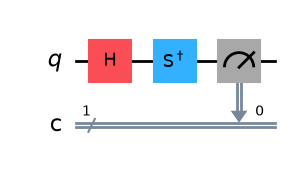

In [7]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
import numpy as np

q = QuantumRegister(1, 'q')
c = ClassicalRegister(1, 'c')
qc = QuantumCircuit(q, c)

# --- Prep step: H makes |+> so the phase change is visible ---
qc.h(q[0])            # |0> -> |+> = (|0> + |1>)/sqrt(2)

# --- Gate ---
qc.sdg(q[0])          # S-dagger gate: phase -i on |1>

# --- State before measurement ---
print("State [amplitude of |0>, amplitude of |1>]:", np.round(Statevector(qc).data, 4))

# --- Measurement ---
qc.measure(q[0], c[0])
counts = AerSimulator().run(qc, shots=1024).result().get_counts()
print("Counts (1024 shots):", counts)

qc.draw(output='mpl')   # last line -> auto-renders circuit diagram

### 8. T† gate (T dagger)
The inverse of T: adds a phase e^{−iπ/4} (−45°) to |1⟩.

State [amplitude of |0>, amplitude of |1>]: [0.7071+0.j  0.5   -0.5j]
Counts (1024 shots): {'0': 513, '1': 511}


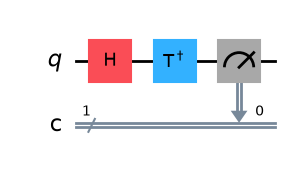

In [8]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
import numpy as np

q = QuantumRegister(1, 'q')
c = ClassicalRegister(1, 'c')
qc = QuantumCircuit(q, c)

# --- Prep step: H makes |+> so the phase change is visible ---
qc.h(q[0])            # |0> -> |+> = (|0> + |1>)/sqrt(2)

# --- Gate ---
qc.tdg(q[0])          # T-dagger gate: phase e^(-i*pi/4) on |1>

# --- State before measurement ---
print("State [amplitude of |0>, amplitude of |1>]:", np.round(Statevector(qc).data, 4))

# --- Measurement ---
qc.measure(q[0], c[0])
counts = AerSimulator().run(qc, shots=1024).result().get_counts()
print("Counts (1024 shots):", counts)

qc.draw(output='mpl')   # last line -> auto-renders circuit diagram

### 9. Identity gate (I)
Does nothing: |0⟩ stays |0⟩. Every shot measures 0.

State [amplitude of |0>, amplitude of |1>]: [1.+0.j 0.+0.j]
Counts (1024 shots): {'0': 1024}


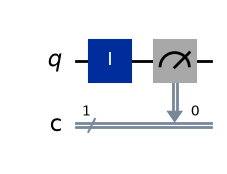

In [9]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
import numpy as np

q = QuantumRegister(1, 'q')
c = ClassicalRegister(1, 'c')
qc = QuantumCircuit(q, c)

# --- Gate ---
qc.id(q[0])           # I gate: no change

# --- State before measurement ---
print("State [amplitude of |0>, amplitude of |1>]:", np.round(Statevector(qc).data, 4))

# --- Measurement ---
qc.measure(q[0], c[0])
counts = AerSimulator().run(qc, shots=1024).result().get_counts()
print("Counts (1024 shots):", counts)

qc.draw(output='mpl')   # last line -> auto-renders circuit diagram